# Can we trust a noisy quantum computer?
## Bell correlations, placement and error detection on IBM hardware

**Qompute 2026, Track 3 / team-12**  
HUNG-YU LIN, XINCHEN GENG, Daniel Cai

HUNG-YU LIN: acceptance review and video. XINCHEN GENG: experiments and method development. Daniel Cai: report/presentation.

This executed notebook reanalyzes saved raw counts. It never submits cloud jobs.
The project follows the general Track 3 requirements. It does **not** claim completion of the optional three-architecture geometry benchmark.

**Question:** When do placement and parity detection improve a result, and what do they cost?


In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
for candidate in [root, root.parent, root / 'Track 3' / 'bell_cloud']:
    if (candidate / 'build_submission.py').is_file():
        root = candidate
        break
else:
    raise FileNotFoundError('Open from repository root, bell_cloud, or its submission directory.')
sys.path.insert(0, str(root))
from build_submission import compute_report, figures
report = compute_report()
print(report['execution'])
print('Both frozen placement replications pass:', all(r['confirmed_improvement'] for r in report['confirmation']))
print('Both controlled-X replications pass:', report['controlled_noise']['confirmed'])
print('Input files hashed:', len(report['input_sha256']))

Offline reanalysis of recorded counts, not a new QPU run.
Both frozen placement replications pass: True
Both controlled-X replications pass: True
Input files hashed: 13


## Verification and baselines

The target is $|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt2$.
Measure three settings, with
$$F=(1+\langle XX\rangle-\langle YY\rangle+\langle ZZ\rangle)/4.$$
The YY minus sign is essential. A classical 00/11 mixture can pass a ZZ-only check.
The ancilla detects odd ZZ parity. A single X fault before the check can be detected; a Z fault cannot. Postselection keeps ancilla-zero shots. This does not implement full error correction.

Saved ideal and synthetic noisy simulator counts provide the baselines below. Synthetic noise uses depolarizing parameters 0.002 / 0.02 on the declared one-/two-qubit gates and readout flip probability 0.02. These are teaching assumptions, not calibrated device noise.


In [2]:
for experiment, variants in report['local'].items():
    for variant, row in variants.items():
        print(f"{experiment:18} {variant:10} F={row['fidelity']:.6f}, retained={row['acceptance_fraction']:.3%}")
for variant, row in report['starter_hardware'].items():
    print(f"Initial QPU {variant:10} F={row['fidelity']:.6f}, retained={row['acceptance_fraction']:.3%}")

ideal              baseline   F=1.000000, retained=100.000%
ideal              protected  F=1.000000, retained=100.000%
synthetic_noisy    baseline   F=0.922852, retained=100.000%
synthetic_noisy    protected  F=0.915340, retained=94.865%
Initial QPU baseline   F=0.968506, retained=100.000%
Initial QPU protected  F=0.951319, retained=97.363%


## Placement: screening followed by two new confirmations

The search covered 176 unordered connected pairs, one prescribed initial orientation each. The candidate was frozen before two new jobs. Each setting has 16,384 shots. Both replications must improve by at least 0.005 and have a positive conservative, attempt-adjusted difference bound. This controls selection from screening more carefully than reporting its maximum.

Compare the selected layout plus reset with the **same layout without reset** to interpret the added operation. No reset-specific improvement was established. Different original-baseline performance across jobs limits any promise of a fixed future gain.


In [3]:
for row in report['confirmation']:
    print(row['stage'])
    for name, result in row['summaries'].items():
        print(f"  {name}: F={result['fidelity']:.6%}; retained={result['retention']:.2%}")
    primary = row['comparisons']['original_baseline']
    print('  Improvement (percentage points):', round(100*primary['improvement'], 4))
    print('  Adjusted difference interval (pp):', [round(100*v, 4) for v in primary['improvement_interval']])
    print('  Reset-specific difference interval (pp):', [round(100*v, 4) for v in row['attribution_comparison']['improvement_interval']])

confirm-01-a
  original_baseline: F=95.806885%; retained=100.00%
  top0_dir0_baseline: F=97.787476%; retained=100.00%
  top0_dir0_baseline_reset: F=97.634888%; retained=100.00%
  Improvement (percentage points): 1.828
  Adjusted difference interval (pp): [0.8131, 2.8409]
  Reset-specific difference interval (pp): [-1.0668, 0.7618]
confirm-01-b
  top0_dir0_baseline_reset: F=97.732544%; retained=100.00%
  top0_dir0_baseline: F=97.650146%; retained=100.00%
  original_baseline: F=90.530396%; retained=100.00%
  Improvement (percentage points): 7.2021
  Adjusted difference interval (pp): [5.9193, 8.4771]
  Reset-specific difference interval (pp): [-0.8375, 1.0022]


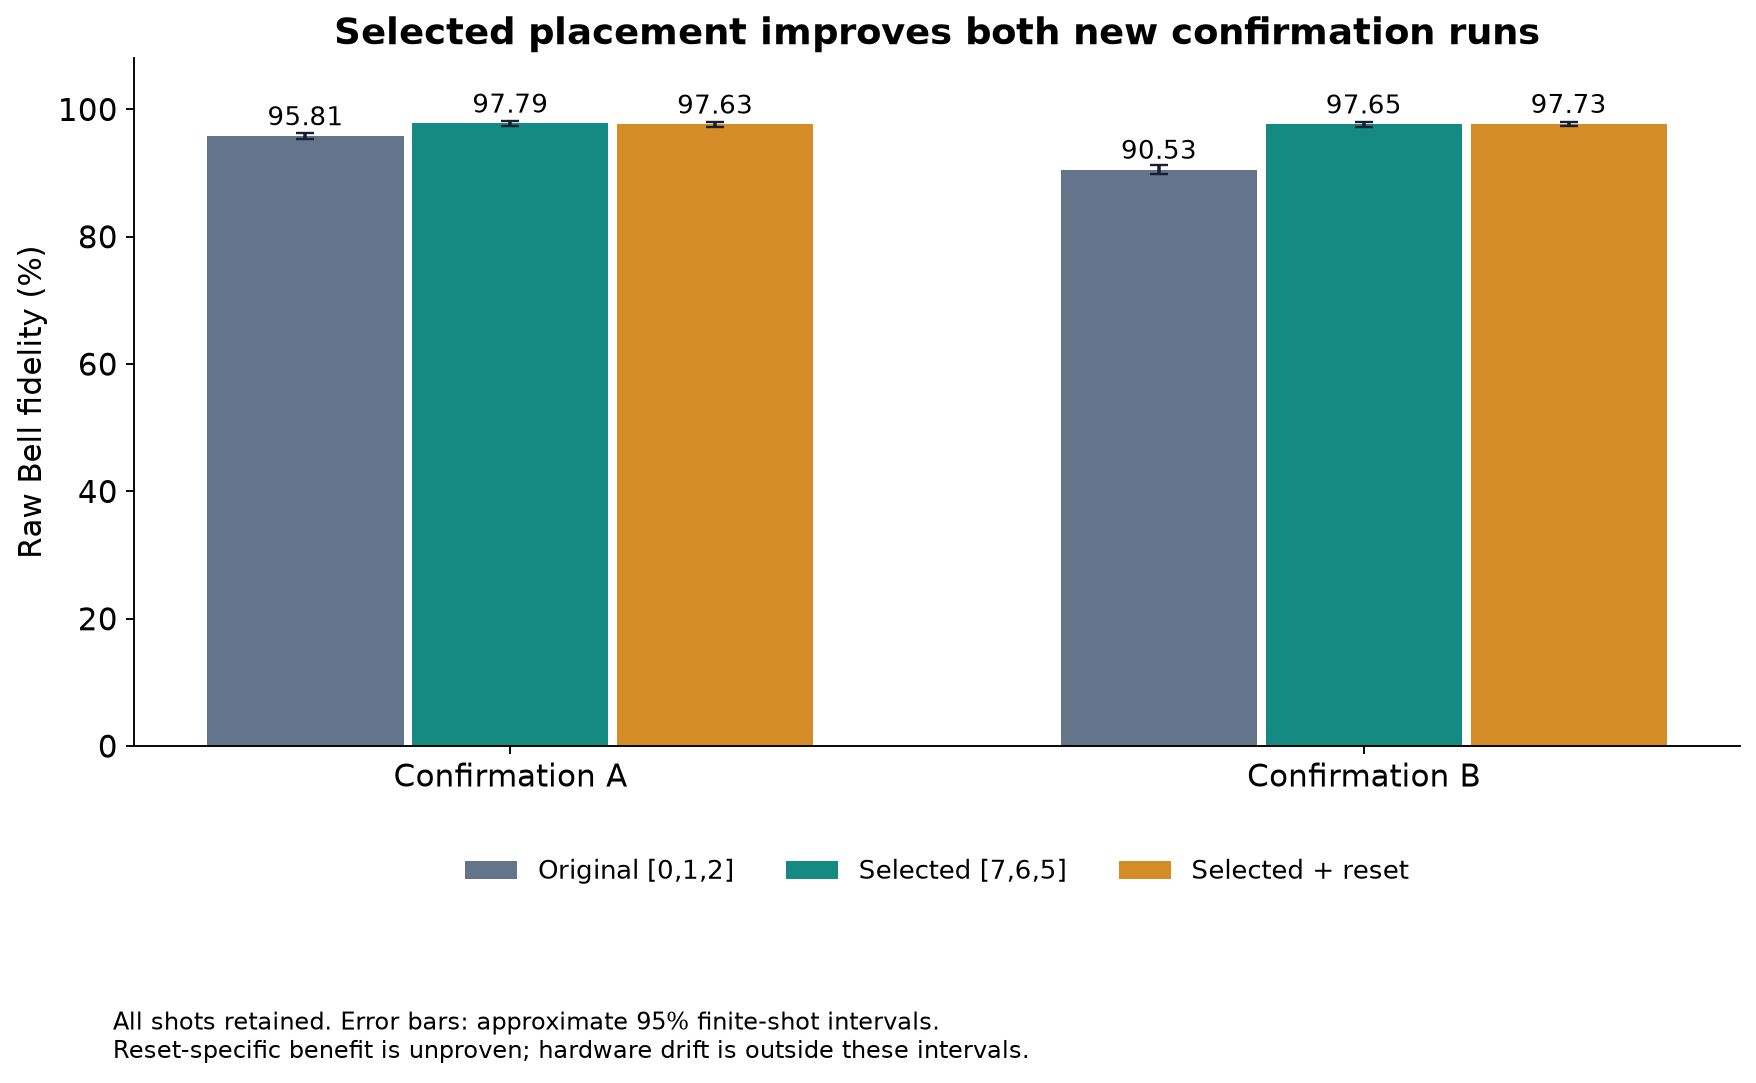

In [4]:
image_names = figures(report, root / 'submission' / 'figures')
from IPython.display import display, Image
display(Image(filename=str(root / 'submission' / 'figures' / 'placement_confirmation.png')))

## Controlled X-error experiment and yield

Each of two new jobs uses nine no-fault circuit copies and one X-fault copy for each variant and basis, with 512 shots per circuit. Counts combine in a fixed 9:1 allocation before filtering. This models a declared 10% X-error mixture, rather than random per-shot Bernoulli fault allocation.

Both jobs must pass the frozen improvement criterion with a positive 99% stratified-bootstrap lower bound. The 0% comparison shares samples and is descriptive. Confidence intervals cover finite-shot variation, excluding drift and systematic readout bias.


stress-01 db86286r6oqs7388qudg
  p0: ordinary=97.9492%, filtered=97.4744%, retained=98.4158%
  p10: ordinary=88.2812%, filtered=97.2299%, retained=88.8672%
  99% difference interval (pp): [8.3762, 9.5269]
stress-02 db8628eil99s73fpco50
  p0: ordinary=97.7973%, filtered=97.5949%, retained=98.3941%
  p10: ordinary=88.1055%, filtered=97.3183%, retained=88.8997%
  99% difference interval (pp): [8.6208, 9.7925]


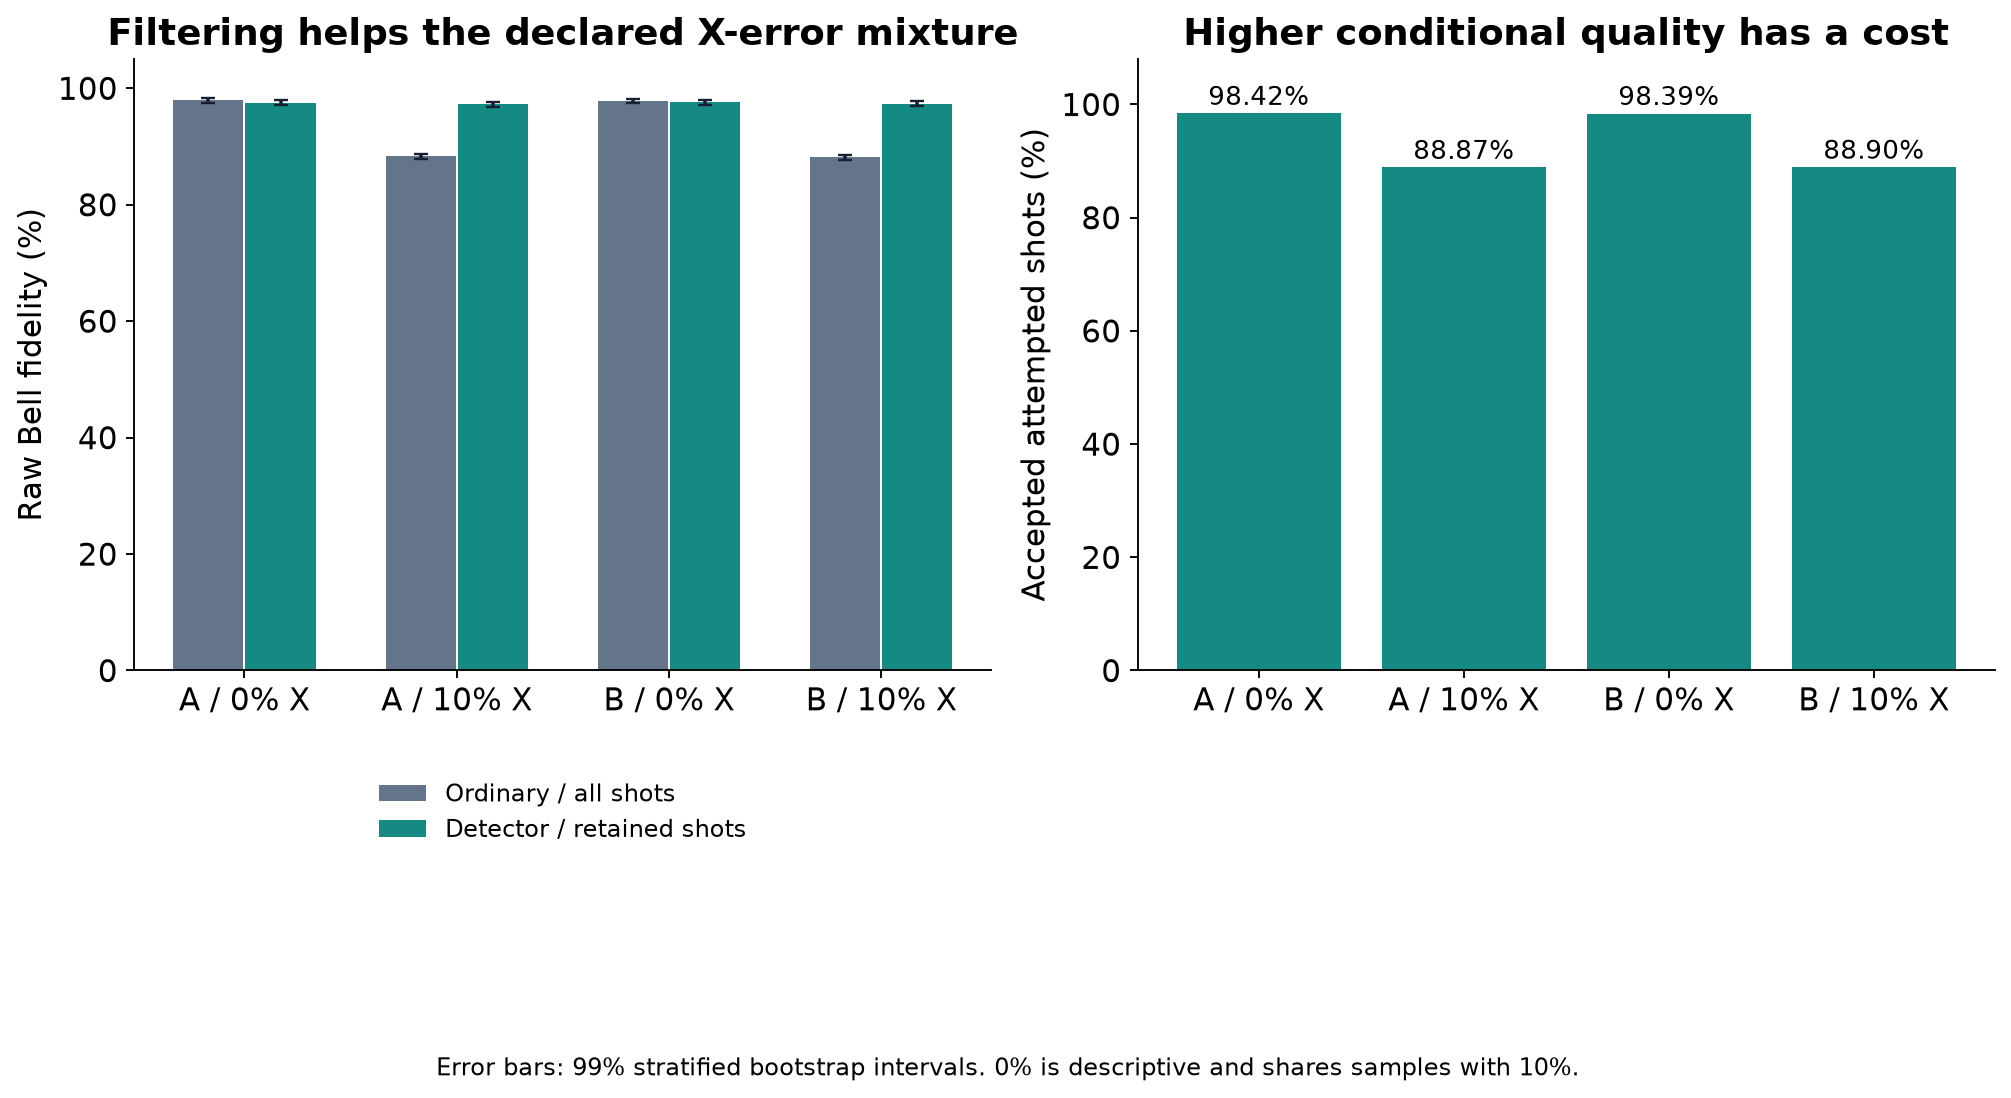

In [5]:
for job in report['controlled_noise']['jobs']:
    print(job['stage'], job['job_id'])
    for name, scenario in job['scenarios'].items():
        baseline, bridge = scenario['baseline'], scenario['bridge']
        print(f"  {name}: ordinary={baseline['fidelity']:.4%}, filtered={bridge['fidelity']:.4%}, retained={bridge['retention']:.4%}")
    print('  99% difference interval (pp):', [round(100*v, 4) for v in job['primary']['confidence_interval_99']])
display(Image(filename=str(root / 'submission' / 'figures' / 'controlled_noise_and_yield.png')))

## Cost and practical interpretation

Ordinary Bell preparation uses one native CZ gate; the initial routed detector uses six; the bridge detector uses four in the measured layouts. The bridge preserves the complete detector unitary while changing connectivity requirements. Fewer gates alone do not prove better noisy performance.

The recorded campaign used 13 completed hardware jobs, 828 circuits and 1,155,072 shots, charging 338 seconds. The recorded remaining allowance was 262 seconds, not a live account balance.


Coverage: 176 / 176
Final recorded charge: 338.0 seconds
Recorded remaining: 262.0 seconds


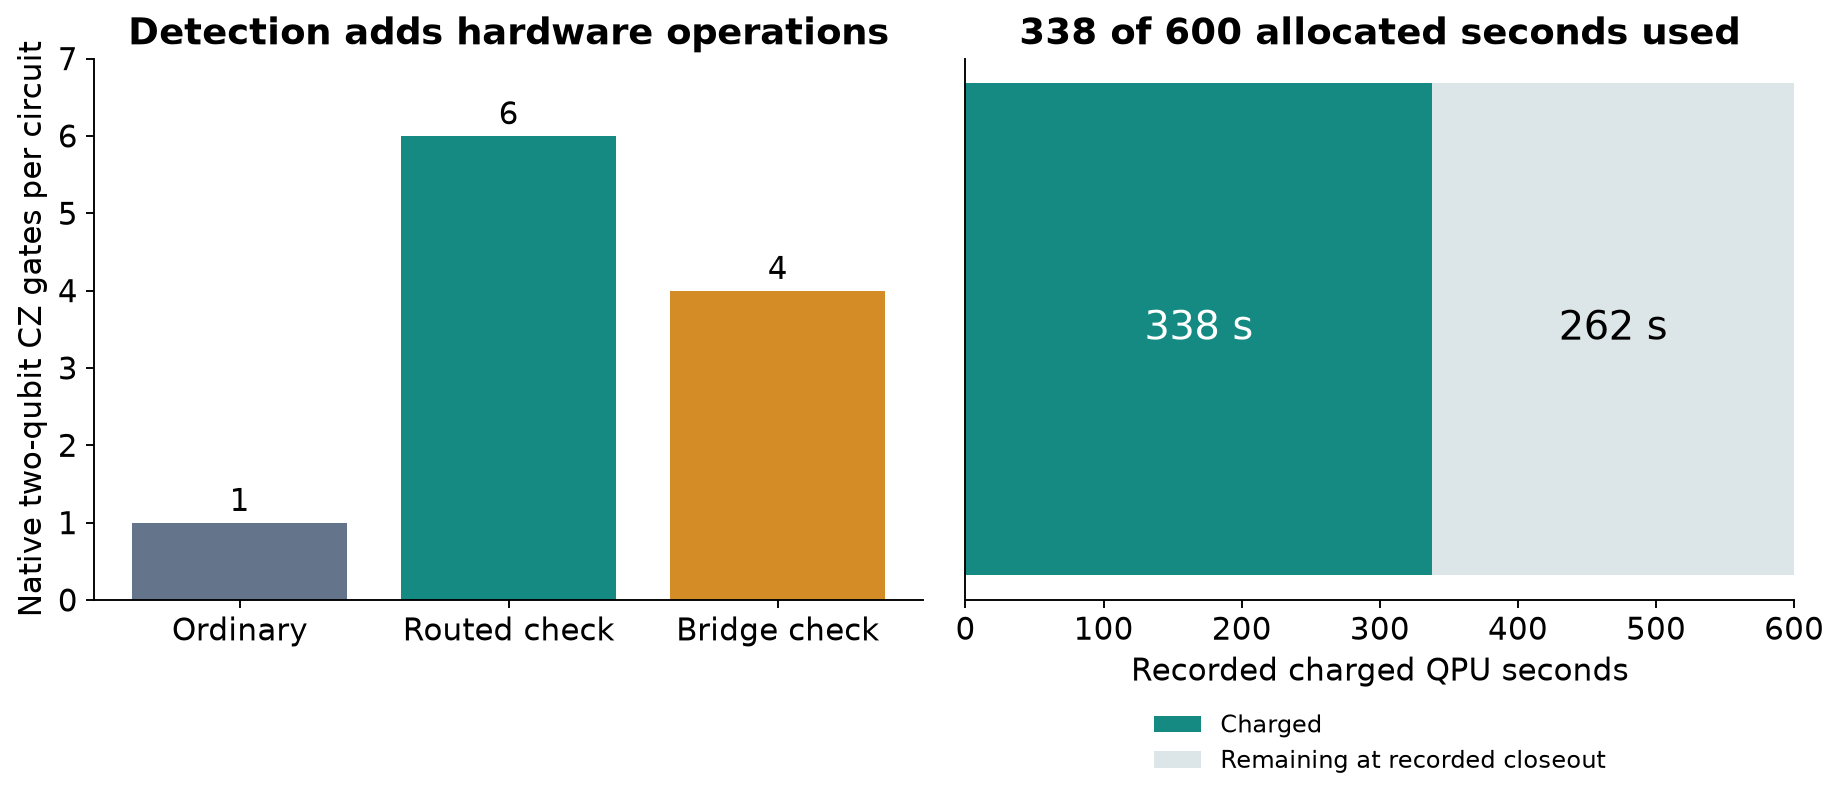

In [6]:
print('Coverage:', report['coverage']['observed_planned_pairs'], '/', report['coverage']['planned_unique_pairs'])
print('Final recorded charge:', report['usage']['total_used_seconds'], 'seconds')
print('Recorded remaining:', report['usage']['remaining_seconds'], 'seconds')
display(Image(filename=str(root / 'submission' / 'figures' / 'hardware_cost.png')))

## Recommendation and societal impact

Cloud platforms should expose calibrated placement choices with repeated same-job reference controls and uncertainty. Users with small compute budgets need raw-count exports, explicit resource costs, and failure results to compare methods fairly.

Use the observed placement benefit as evidence among tested configurations. Use the injected-error experiment as evidence for conditional X-error filtering. Neither result establishes quantum advantage, general fault tolerance, or readiness for high-stakes decisions. Report accepted shots alongside fidelity so discarded outputs do not disappear from the assessment.

## Scope and remaining architecture work

The optional geometry PDF asks for three specified models, fixed output ports, common numerical noise assumptions and nine core cases. Those complete definitions are absent from the supplied materials. This submission does not substitute invented definitions or claim architecture superiority. The present scope is a verified small experiment with ideal/noisy references, suppression through placement, error detection, resource accounting and limitations under the general Track 3 prompt.

## Sources and reproduction

- [Official Track 3 requirements](https://github.com/sandraalhames/Qompute-2026#track-3-can-we-trust-a-noisy-quantum-computer)
- [Project code and raw evidence](https://github.com/gengx-prog/qompute-2026-fair-aid-qaoa/tree/main/Track%203/bell_cloud)
- [IBM error mitigation and suppression guide](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques)
- The neighboring geometry challenge PDF is credited to Steven Rayan / quanTA, University of Saskatchewan.

Run `python build_submission.py` from `Track 3/bell_cloud` after installing `requirements-submission.txt`. A single Python namespace executes all code cells and records their real outputs. The notebook also runs in Jupyter. This rebuilds local analyses and figures only. Saved QPU evidence and frozen plans stay unchanged. Bootstrap percentile endpoints may vary slightly across numerical builds and platforms; point estimates and conclusions should agree.
